In [1]:
print("Importing----")

import os, sys, time, subprocess, tempfile
from coffea import processor
import coffea.util
import matplotlib.pyplot as plt
import yaml

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities, scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions
utilities.set_plot_style()
%matplotlib inline
import mplhep as hep


Importing----


In [2]:
print("----Files----")

yaml_file_path = '../../configs/ntuples/signal_4mu_v10.yaml'
# Open and read the YAML file
with open(yaml_file_path, 'r') as file:
    data = yaml.safe_load(file)
signals_all = list(data["llpNanoAOD_v2"]["samples"].keys())


data = functions.get_data_files()




bgs= [
    
 #     "TTJets",
 #    "DYJetsToMuMu_M10to50",
      
 #         "QCD_Pt1000",
 #      # "QCD_Pt800To1000", #failed

 #      "QCD_Pt600To800",
 #       "QCD_Pt470To600",
 #        "QCD_Pt300To470",
     
 #      "QCD_Pt170To300",
 #         "QCD_Pt120To170",
 # "DYJetsToMuMu_M50",
 #        "QCD_Pt80To120",
 #         "QCD_Pt50To80",
 #       "QCD_Pt30To50",
 #       "QCD_Pt20To30", #error
 #         "QCD_Pt15To20", #error
 
 
      # "DYJetsToMuMu_M10to50",
       "DYJetsToLL_M50",
     
]

----Files----


In [3]:
print("========Runner=======")

runner = processor.Runner(
    executor=processor.IterativeExecutor(),
    # executor=processor.FuturesExecutor(),
    # executor=processor.DaskExecutor(client=client),
    schema = llpnanoaodschema.LLPNanoAODSchema,
    skipbadfiles=True,
)
channel_name = "base_ljIso" #"cr_Zmumu_muon_hits"
hist_collection = "dyjet_study"
print("=======Processor=========")

p = sidm_processor.SidmProcessor([channel_name,  ], [hist_collection])

========Runner=======
=======Processor=========


In [4]:
print("========Fileset========")
max_files_bg = 1
max_files_data =1
max_files_signal = 1

# fileset = utilities.make_fileset([data[0]], "llpNanoAOD_v2",
#              max_files=max_files_data,location_cfg="data_skimmed.yaml")
# output = runner.run(fileset, treename="Events", processor_instance=p)

# fileset = utilities.make_fileset([signals_all[0]], "llpNanoAOD_v2", max_files=max_files_signal, location_cfg="signal_4mu_v10.yaml")
# output= runner.run(fileset, treename="Events", processor_instance=p)

fileset = utilities.make_fileset(bgs, "skimmed_llpNanoAOD_v2", location_cfg="backgrounds.yaml", max_files=max_files_bg)
output = runner.run(fileset, treename="Events", processor_instance=p)




Processing 100% ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/1 [ 0:00:07 < 0:00:00 | ? chunk/s ]

DYJetsToLL_M50 is simulation. Scaling histograms or cutflows according to lumi*xs.


In [5]:
print(output["out"]["DYJetsToLL_M50"]["hists"].keys())

dict_keys(['muon_trkNumPixelHits', 'mu_lj_pfMu_max_trkNumPixelHits', 'mu_lj_pfMu_min_trkNumPixelHits', 'mu_lj_pfMu_min_trkNumTrkLayers', 'muon_muon_invmass', 'muon_muon_invmass_highRange', 'muon_n', 'electron_n', 'dsaMuon_n', 'photon_n', 'mu_lj_mass', 'mu0_mu1_dphi_invMass', 'mu_mu_dphi_invMass', 'mu_mu_dphi', 'mu_mu_inv_mass', 'jet_n', 'jet_pt', 'jet_eta_phi', 'muon_pt', 'muon_eta_phi', 'muN_muLj_muN_diff', 'mu_lj_muonN', 'mu_lj_pfMu_n', 'mu_lj_dsaMu_n', 'mu_lj_pt', 'mu_lj_muon_pt', 'mu_lj_pfMuon_pt', 'mu_lj_dsaMuon_pt', 'jet0Pt_muLj0_pt', 'jet0_muLj0_dPhi', 'mu0_mu1_dphi', 'mu0_mu1_dR', 'jet0_muLj0_dR', 'jet1_muLj0_dR', 'jet1_muLj0_dPhi', 'jet1Pt_muLj0_pt', 'mu0_mu1_pt', 'jet0Pt_diMuon_dR', 'jet0Pt_diMuon_pt', 'jet0Pt_diMuon_dPhi', 'muon_dthits_cschits', 'muon_dthits_cschits_leading', 'mu_lj_eta_phi', 'egm_lj_eta_phi', 'muon_dthits_plus_cschits', 'muon_dthits_plus_cschits_leading_vs_dR', 'muon_dthits_plus_cschits_subleading_vs_dR', 'muon_dthits_plus_cschits_leading_vs_dR_event_mask',

=======Plotting=======


[StairsArtists(stairs=<matplotlib.patches.StepPatch object at 0x7f07a1d3ff80>, errorbar=<ErrorbarContainer object of 3 artists>, legend_artist=<ErrorbarContainer object of 3 artists>)]

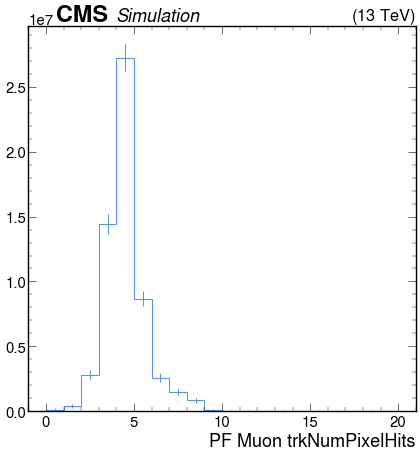

In [6]:
from matplotlib.colors import LogNorm

print("=======Plotting=======")

histogram1 = output["out"][bgs[0]]["hists"]["muon_trkNumPixelHits"][channel_name, :]
utilities.plot(histogram1)

# plt.figure()

=======Plotting=======


=======Plotting=======


ColormeshArtists(pcolormesh=<matplotlib.collections.QuadMesh object at 0x7f07a2a898b0>, cbar=<matplotlib.colorbar.Colorbar object at 0x7f07a2a89010>, text=[])

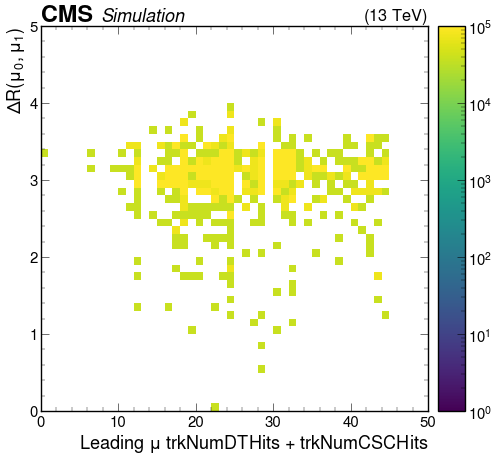

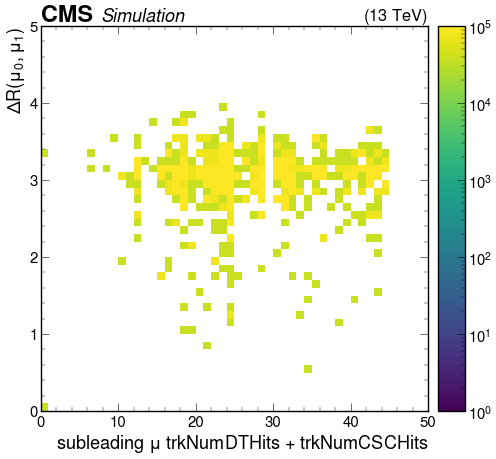

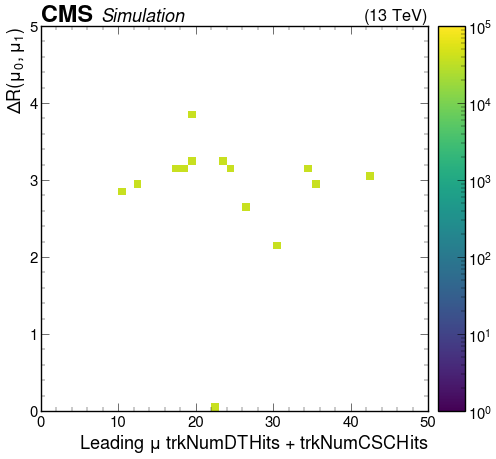

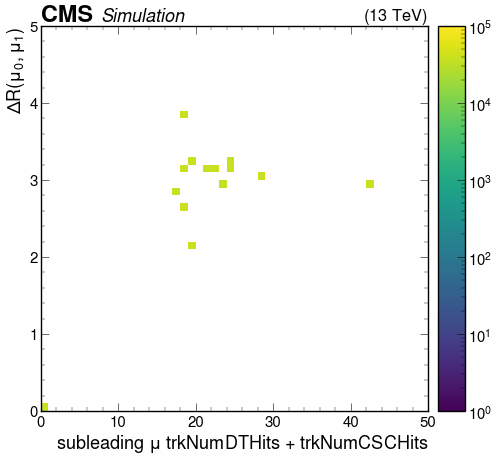

In [7]:
from matplotlib.colors import LogNorm

print("=======Plotting=======")

histogram1 = output["out"][bgs[0]]["hists"]["muon_dthits_plus_cschits_leading_vs_dR"][channel_name, :, :]

utilities.plot(histogram1, norm=LogNorm(1, 1e5))

plt.figure()

histogram1 = output["out"][bgs[0]]["hists"]["muon_dthits_plus_cschits_subleading_vs_dR"][channel_name, :, :]

utilities.plot(histogram1, norm=LogNorm(1, 1e5))

print("=======Plotting=======")
plt.figure()

histogram1 = output["out"][bgs[0]]["hists"]["muon_dthits_plus_cschits_leading_vs_dR_event_mask"][channel_name, :, :]

utilities.plot(histogram1, norm=LogNorm(1, 1e5))

plt.figure()

histogram1 = output["out"][bgs[0]]["hists"]["muon_dthits_plus_cschits_subleading_vs_dR_event_mask"][channel_name, :, :]

utilities.plot(histogram1, norm=LogNorm(1, 1e5))

=======Plotting=======


[StairsArtists(stairs=<matplotlib.patches.StepPatch object at 0x7f07a2ad2ff0>, errorbar=None, legend_artist=None)]

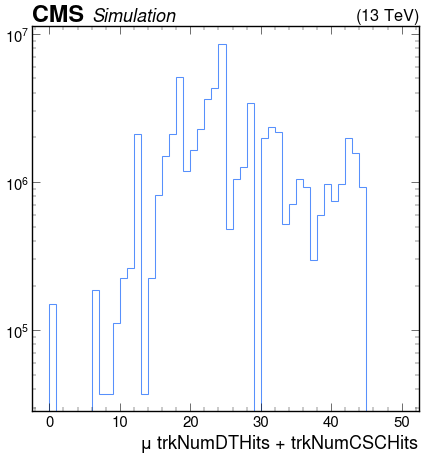

In [8]:
print("=======Plotting=======")
# histogram1 = output["out"][S[0]]["hists"]["muon_dz_innerVz_diff"][channelname,:]
# histogram1 = output["out"][data[0]]["hists"]["muon_dthits_plus_cschits"][channel_name,:]
histogram1 = output["out"][bgs[0]]["hists"]["muon_dthits_plus_cschits"][channel_name,:]
plt.yscale("log")

utilities.plot(histogram1, yerr=False)
